## Daftar Isi

<div class="alert alert-block alert-info" style="margin-top: 20px">

1.  [Importing Libraries](#0)<br>
2.  [Downloading and Importing Data](#2)<br>
3.  [Visualizing Data using Matplotlib](#4) <br>
4.  [Pie Charts](#6) <br>
5.  [Box Plots](#8) <br>
6.  [Scatter Plots](#10) <br>
7.  [Bubble Plots](#12) <br>

</div>


# Importing Libraries<a id="0"></a>


In [1]:
# Import modul utama
# Import matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np  # berguna untuk banyak komputasi ilmiah di Python
import pandas as pd  # pustaka struktur data utama

mpl.style.use("ggplot")  # tema plot dengan gaya ggplot

# Periksa versi Matplotlib terbaru
print("Versi Matplotlib:", mpl.__version__)

Versi Matplotlib: 3.11.2


## Importing Data <a id="2"></a>
Dataset: Imigrasi ke Kanada dari tahun 1980 hingga 2013 - [International migration flows to and from selected countries - The 2015 revision](https://www.un.org/development/desa/pd/data/international-migration-flows) dari website United Nation's 

Dalam lab ini, data yang digunakan akn berfokus pada Imigrasi Kanada dan menggunakan **dataset yang sudah dibersihkan** dan dapat diunduh dari <a href="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.csv">disini</a>.<br><br>
Anda dapat merujuk ke lab tentang pra-pemrosesan data di mana dataset ini dibersihkan untuk penyegaran cepat keterampilan Pandas, melalui [Data pre-processing with Pandas](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/june2023_updates/Module%201/DV0101EN-Exercise-Dataset-Preprocessing-Exploring-with-Pandas.ipynb)


In [2]:
df_canada = pd.read_csv("../../data/raw/Canada.csv")
print("Data sudah dibaca ke dalam dataframe pandas")

Data sudah dibaca ke dalam dataframe pandas


In [3]:
df_canada.head()

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1223,856,702,560,716,561,539,620,603,15699
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,1,1,0,0,0,0,1,1,15


Cari tahu berapa banyak entri yang ada dalam dataset.

In [4]:
df_canada.shape

(195, 39)

# Visualizing Data using Matplotlib<a id="4"></a>

Untuk memudahkan pembuatan grafik data, pertama-tama tetapkan nama negara (`Country`) sebagai indeks, ini berguna untuk mencari negara dengan cepat menggunakan metode `.loc`.

In [5]:
df_canada.set_index("Country", inplace=True)

In [6]:
df_canada.index.name = None

In [7]:
df_canada.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,1,1,0,0,0,0,1,1,15


Perhatikan bahwa nama-nama negara sekarang berfungsi sebagai indeks.

In [8]:
print("data dimensions:", df_canada.shape)

data dimensions: (195, 38)


Terakhir, buat daftar tahun dari 1980 - 2013, ini akan berguna saat mulai membuat grafik data.

In [9]:
years = list(map(str, range(1980, 2014)))

# Pie Charts <a id="6"></a>

Pie chart atau diagram lingkaran adalah grafik melingkar yang menampilkan proporsi numerik dengan membagi lingkaran (atau pai) menjadi irisan-irisan yang proporsional. Anda mungkin sudah familiar dengan diagram lingkaran karena banyak digunakan dalam bisnis dan media. Kita dapat membuat diagram lingkaran di Matplotlib dengan memberikan kata kunci `kind=pie`.

Mari kita gunakan diagram lingkaran untuk mengeksplorasi proporsi (persentase) imigran baru yang dikelompokkan menurut benua untuk seluruh periode waktu dari tahun 1980 hingga 2013.


Langkah 1: Kumpulkan data.

Kita akan menggunakan metode `groupby` dari *pandas* untuk meringkas data imigrasi berdasarkan `Continent`. Proses umum dari `groupby` melibatkan langkah-langkah berikut:

1.  **Split:** Membagi data ke dalam beberapa kelompok berdasarkan kriteria tertentu.
2.  **Apply:** Menerapkan fungsi pada setiap kelompok secara independen:
    .sum()
    .count()
    .mean()
    .std()
    .aggregate()
    .apply()
    .etc..
3.  **Combine:** Menggabungkan hasil-hasil tersebut ke dalam sebuah struktur data.


<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/Mod3Fig4SplitApplyCombine.png" height="400" align="center">


In [10]:
# kelompokkan negara berdasarkan benua dan terapkan fungsi sum()
df_continents = df_canada.groupby("Continent").sum()

In [11]:
# Catatan: output dari metode groupby adalah objek `groupby`.
# Kita tidak dapat menggunakannya lebih lanjut sampai kita menerapkan sebuah fungsi (misalnya .sum())

print(type(df_canada.groupby("Continent")))

<class 'pandas.api.typing.DataFrameGroupBy'>


In [12]:
df_continents.head()

,Region,DevName,1980,1981,1982,1983,1984,1985,1986,1987,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Continent,,,,,,,,,,,,,,,,,,,,,
Africa,Northern AfricaMiddle AfricaWestern AfricaSout...,Developing regionsDeveloping regionsDeveloping...,3951,4363,3819,2671,2639,2650,3782,7494,...,27523,29188,28284,29890,34534,40892,35441,38083,38543,618948
Asia,Southern AsiaWestern AsiaWestern AsiaWestern A...,Developing regionsDeveloping regionsDeveloping...,31025,34314,30214,24696,27274,23850,28739,43203,...,159253,149054,133459,139894,141434,163845,146894,152218,155075,3317794
Europe,Southern EuropeSouthern EuropeWestern EuropeEa...,Developed regionsDeveloped regionsDeveloped re...,39760,44802,42720,24638,22287,20844,24370,46698,...,35955,33053,33495,34692,35078,33425,26778,29177,28691,1410947
Latin America and the Caribbean,CaribbeanSouth AmericaCaribbeanCaribbeanCentra...,Developing regionsDeveloping regionsDeveloping...,13081,15215,16769,15427,13678,15171,21179,28471,...,24747,24676,26011,26547,26867,28818,27856,27173,24950,765148
Northern America,Northern AmericaNorthern America,Developed regionsDeveloped regions,9378,10030,9074,7100,6661,6543,7074,7705,...,8394,9613,9463,10190,8995,8142,7677,7892,8503,241142


Langkah 2: Plot data. Kita akan memasukkan kata kunci `kind = 'pie'`, beserta parameter tambahan berikut:

*   `autopct` -  adalah string atau fungsi yang digunakan untuk memberi label pada irisan dengan nilai numeriknya. Label akan ditempatkan di dalam irisan. Jika berupa string format, label akan menjadi `fmt%pct`.
*   `startangle` - Memutar titik awal diagram lingkaran sebesar sudut derajat berlawanan arah jarum jam dari sumbu x.
*   `shadow` - Menggambar bayangan di bawah pai (untuk memberikan kesan 3D).


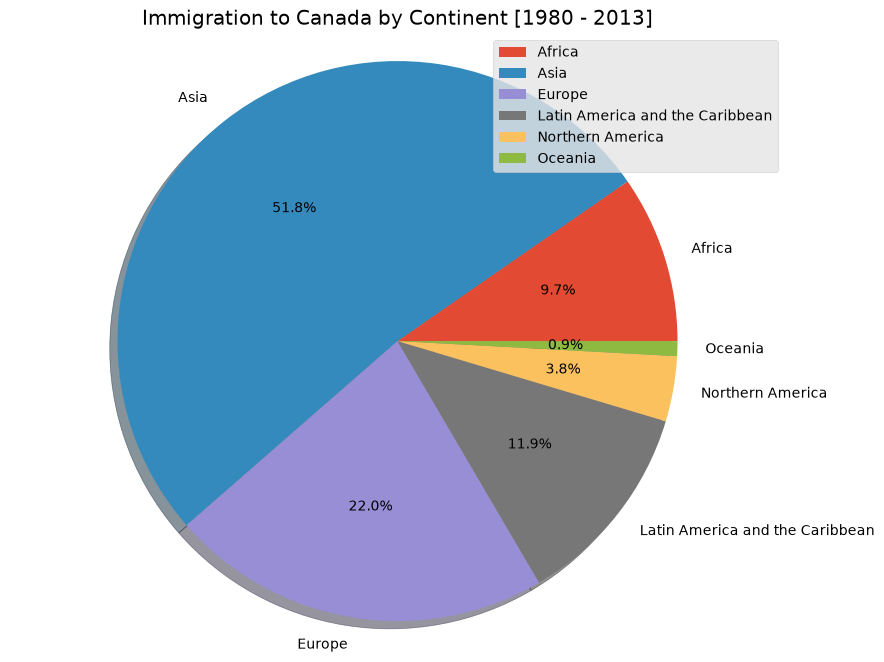

In [13]:
# autopct create %, start angle represent starting point
df_continents["Total"].plot(
    kind="pie",
    figsize=(10, 8),
    autopct="%1.1f%%",  # tambahkan dalam persentase
    shadow=True,
)

plt.title("Immigration to Canada by Continent [1980 - 2013]")
plt.axis(
    "equal"
)  # Mengatur tampilan diagram lingkaran agar menyerupai bentuk lingkaran.
plt.legend(labels=df_continents.index, loc="upper right")

plt.savefig("../outputs/pie_chart_without_explode.png", dpi=200, bbox_inches="tight")
plt.show()

Visual di atas kurang jelas, angka dan teks tumpang tindih di beberapa bagian. Mari kita lakukan beberapa modifikasi untuk meningkatkan visualnya:

*   Hapus label teks pada diagram lingkaran dengan memberikan parameter `legend` dan tambahkan sebagai legenda terpisah menggunakan `plt.legend()`.
*   Geser persentase agar berada tepat di luar diagram lingkaran dengan memberikan parameter `pctdistance`.
*   Masukkan serangkaian warna khusus untuk benua dengan memberikan parameter `colors`.
*   **Explode** diagram lingkaran tersebut digunakan untuk menekankan tiga benua terendah (Afrika, Amerika Utara, dan Amerika Latin serta Karibia) dengan memasukkan parameter `explode`


In [14]:
color_list = ["gold", "yellowgreen", "lightcoral", "lightskyblue", "lightgreen", "pink"]
explode_list = [
    0.1,
    0,
    0,
    0,
    0.1,
    0.1,
]  # rasio untuk setiap benua yang digunakan untuk mengimbangi setiap irisan.

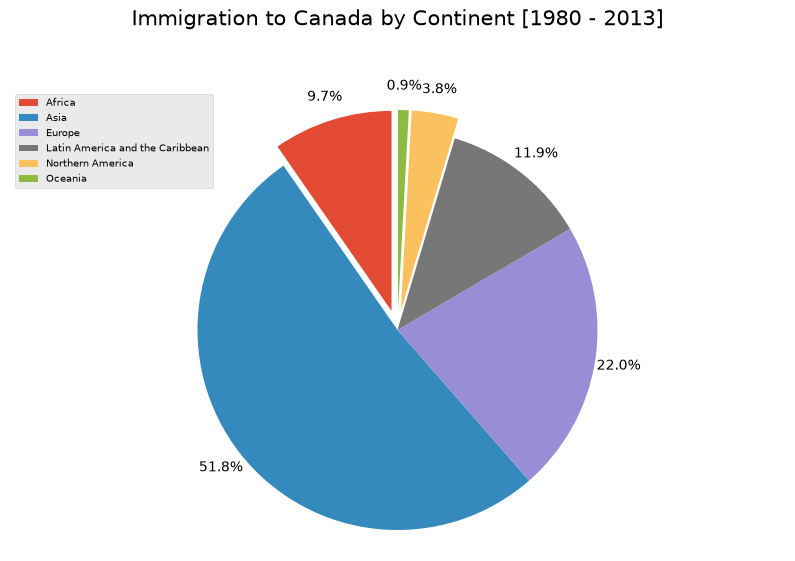

In [15]:
# Buat plot
df_continents["Total"].plot(
    kind="pie",
    figsize=(10, 6),
    autopct="%1.1f%%",
    startangle=90,
    labels=None,  # matikan label pada diagram lingkaran
    pctdistance=1.12,  # rasio antara pusat setiap irisan pai dan awal teks yang dihasilkan oleh autopct
    color=color_list,  # tambahkan warna khusus
    explode=explode_list,  # 'explode' di 3 benua terendah
)

# Perbesar ukuran judul sebesar 12% agar sesuai dengan pctdistance.
plt.title("Immigration to Canada by Continent [1980 - 2013]", y=1.12, fontsize=15)

plt.axis("equal")

# tambahkan legenda
plt.legend(labels=df_continents.index, loc="upper left", fontsize=7)

plt.savefig(
    "../outputs/pie_charts_immigration_by_continent.png", dpi=200, bbox_inches="tight"
)
plt.show()

**Pertanyaan:** Dengan menggunakan diagram lingkaran, jelaskan proporsi (persentase) imigran baru yang dikelompokkan berdasarkan benua pada tahun 2013.

**Catatan**: Anda mungkin perlu bereksperimen dengan nilai eksplorasi untuk memperbaiki nilai irisan yang tumpang tindih.


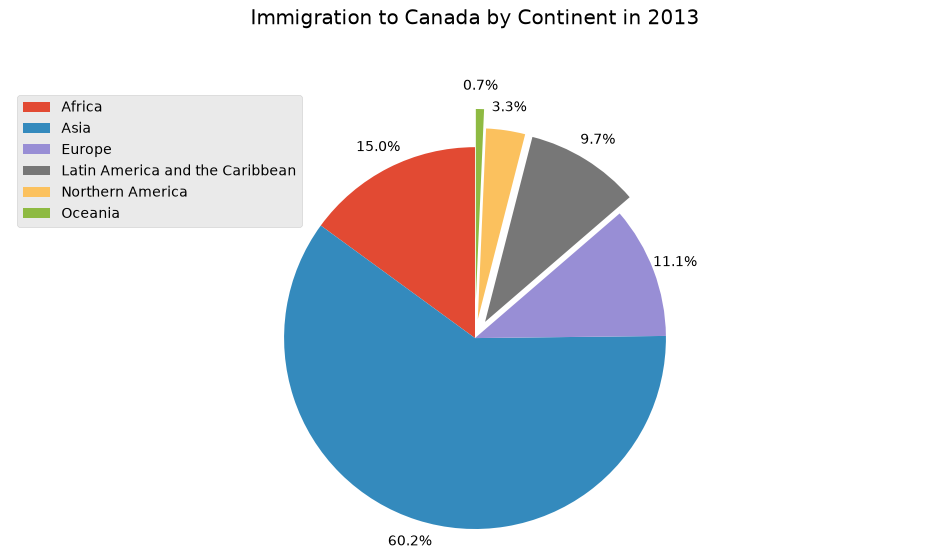

In [16]:
explode_list2 = [
    0.0,
    0,
    0,
    0.1,
    0.1,
    0.2,
]  # rasio untuk setiap benua yang digunakan untuk mengimbangi setiap irisan.

# Buat plot
df_continents["2013"].plot(
    kind="pie",
    figsize=(12, 6),
    autopct="%1.1f%%",
    startangle=90,
    labels=None,
    pctdistance=1.12,
    explode=explode_list2,
)

plt.title("Immigration to Canada by Continent in 2013", y=1.12)
plt.axis("equal")

plt.legend(labels=df_continents.index, loc="upper left")

plt.savefig(
    "../outputs/pie_charts_immigration_by_continent_2013.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# Box Plots <a id="8"></a>

`Box plot` adalah cara untuk merepresentasikan *distribusi* data secara statistik melalui lima dimensi utama:

*   **Minimum:** Angka terkecil dalam dataset, tidak termasuk outlier.
*   **First quartile:** Angka tengah antara nilai `minimum` dan nilai `median`.
*   **Second quartile (Median):** Angka tengah dari dataset (yang sudah diurutkan).
*   **Third quartile:** Angka tengah antara `median` dan `maksimum`.
*   **Maximum:** Angka terbesar dalam dataset, tidak termasuk outlier.


<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/boxplot_complete.png" width="440," align="center">


Untuk membuat `boxplot`, kita dapat menggunakan `kind=box` dalam metode `plot` yang dipanggil pada series atau dataframe *pandas*.

Mari kita buat diagram kotak untuk imigran Jepang antara tahun 1980 - 2013.


Langkah 1: Dapatkan subset dari dataset. Meskipun kita hanya mengekstrak data untuk satu negara, kita akan memperolehnya sebagai dataframe. Ini akan membantu kita dalam memanggil metode `dataframe.describe()` untuk melihat persentilnya.


In [17]:
df_japan = df_canada.loc[["Japan"], years].transpose()
df_japan.head()

,Japan
1980,701
1981,756
1982,598
1983,309
1984,246


Langkah 2: Plot dengan memasukkan `kind='box'`.


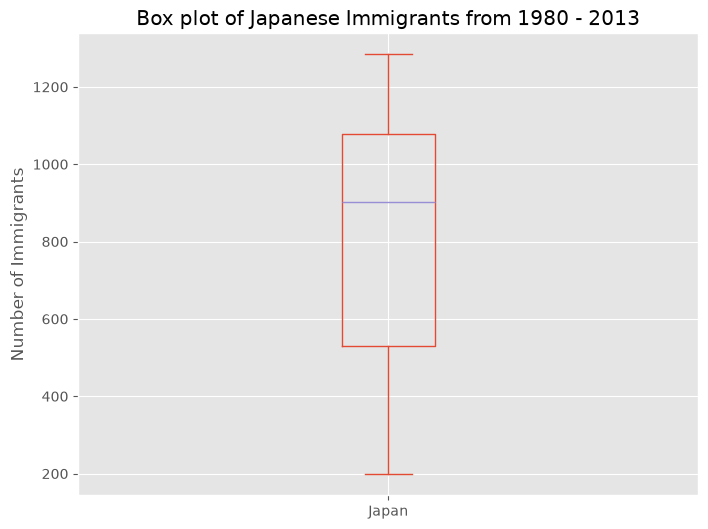

In [18]:
df_japan.plot(kind="box", figsize=(8, 6))

plt.title("Box plot of Japanese Immigrants from 1980 - 2013")
plt.ylabel("Number of Immigrants")

plt.savefig("../outputs/box_plot_japan_immigrants.png", dpi=200, bbox_inches="tight")
plt.show()

Dari grafik di atas, kita dapat langsung membuat beberapa pengamatan penting:

1.  Jumlah imigran minimum sekitar 200 (min), jumlah maksimum sekitar 1300 (max), dan jumlah imigran median sekitar 900 (median).
2.  25% dari tahun-tahun dalam periode 1980 - 2013 memiliki jumlah imigran tahunan sekitar 500 orang atau kurang (Kuartil pertama).
3.  75% dari tahun-tahun dalam periode 1980 - 2013 memiliki jumlah imigran tahunan sekitar 1100 atau kurang (Kuartil ketiga).

Kita dapat melihat angka sebenarnya dengan memanggil metode `describe()` pada dataframe.

In [19]:
df_japan.describe()

,Japan
count,34.000000
mean,814.911765
std,337.219771
min,198.000000
25%,529.000000
50%,902.000000
75%,1079.000000
max,1284.000000


Salah satu manfaat utama dari box plot adalah untuk membandingkan distribusi beberapa dataset. Pada salah satu praktikum sebelumnya, kita mengamati bahwa China dan India memiliki tren imigrasi yang sangat mirip. Mari kita analisis kedua negara ini lebih lanjut menggunakan box plot.

**Pertanyaan:** Bandingkan distribusi jumlah imigran baru dari China dan India untuk periode 1980 - 2013.

Langkah 1: Dapatkan dataset untuk China dan India dan beri nama dataframe tersebut **df_CI**.

In [20]:
df_CI = df_canada.loc[["China", "India"], years].transpose()
df_CI.head()

,China,India
1980,5123,8880
1981,6682,8670
1982,3308,8147
1983,1863,7338
1984,1527,5704


Mari kita lihat persentil yang terkait dengan kedua negara menggunakan metode `describe()`.

In [21]:
df_CI.describe()

,China,India
count,34.000000,34.000000
mean,19410.647059,20350.117647
std,13568.230790,10007.342579
min,1527.000000,4211.000000
25%,5512.750000,10637.750000
50%,19945.000000,20235.000000
75%,31568.500000,28699.500000
max,42584.000000,36210.000000


Langkah 2: Plot data.

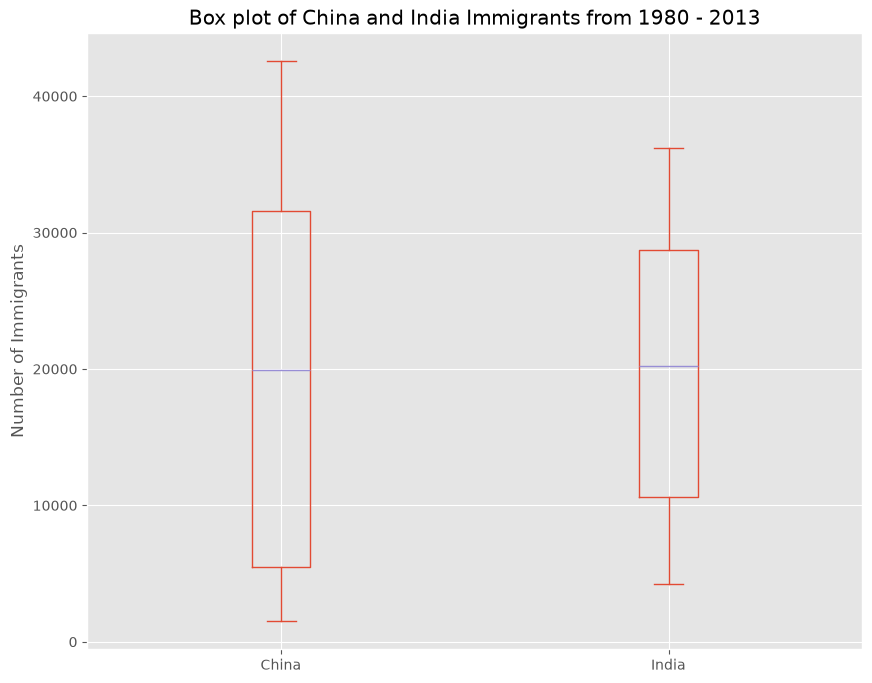

In [22]:
df_CI.plot(kind="box", figsize=(10, 8))

plt.title("Box plot of China and India Immigrants from 1980 - 2013")
plt.ylabel("Number of Immigrants")

plt.savefig(
    "../outputs/box_plot_china_india_immigrants.png", dpi=200, bbox_inches="tight"
)
plt.show()

Kita dapat mengamati bahwa, meskipun kedua negara memiliki jumlah imigran rata-rata yang hampir sama (~20.000), sebaran populasi imigran di China lebih luas daripada di India. Populasi maksimum dari India untuk tahun tertentu (36.210) sekitar 15% lebih rendah daripada populasi maksimum dari China (42.584).

Jika Anda lebih suka membuat plot kotak horizontal, Anda dapat memberikan parameter `vert` pada fungsi **plot** dan menetapkannya ke *False*. Anda juga dapat menentukan warna yang berbeda jika Anda tidak menyukai warna merah default.

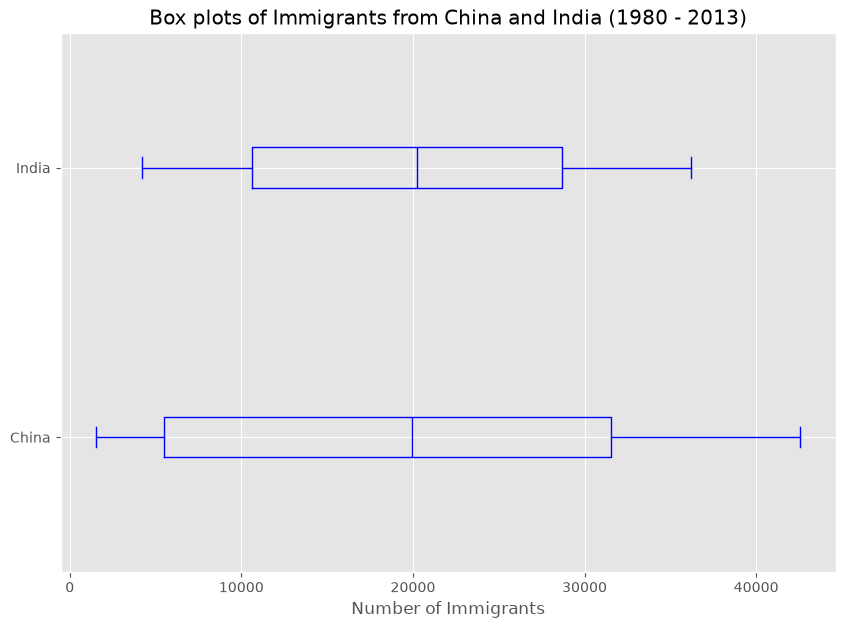

In [23]:
df_CI.plot(kind="box", figsize=(10, 7), color="blue", vert=False)

plt.title("Box plots of Immigrants from China and India (1980 - 2013)")
plt.xlabel("Number of Immigrants")

plt.savefig("../outputs/horizontal_box_plot.png", dpi=200, bbox_inches="tight")
plt.show()

**Subplots**

Seringkali kita mungkin ingin menampilkan beberapa plot dalam satu gambar yang sama. Misalnya, kita mungkin ingin melakukan perbandingan berdampingan antara box plot dan line plot imigrasi China dan India.

Untuk memvisualisasikan beberapa plot secara bersamaan, kita dapat membuat **`figure`** (kanvas keseluruhan) dan membaginya menjadi **`subplots`**, yang masing-masing berisi satu plot. Dengan **subplots**, kita biasanya bekerja dengan **artist layer** alih-alih **scripting layer**.

Sintaks tipikalnya adalah : <br>

```python
    fig = plt.figure() # create figure
    ax = fig.add_subplot(nrows, ncols, plot_number) # create subplots
```

Dimana

*   `nrows` dan `ncols` digunakan untuk membagi gambar secara konseptual menjadi (`nrows` * `ncols`) sub-axes,
*   `plot_number` digunakan untuk mengidentifikasi subplot tertentu yang akan dibuat oleh fungsi ini di dalam grid hipotetis. `plot_number` dimulai dari 1, bertambah secara berurutan di setiap baris, dan memiliki nilai maksimum `nrows` * `ncols` seperti yang ditunjukkan di bawah ini.

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/Mod3Fig5Subplots_V2.png" width="500" align="center">


Kita kemudian dapat menentukan subplot mana tempat setiap plot akan ditempatkan dengan memberikan parameter `ax` pada metode `plot()` sebagai berikut:

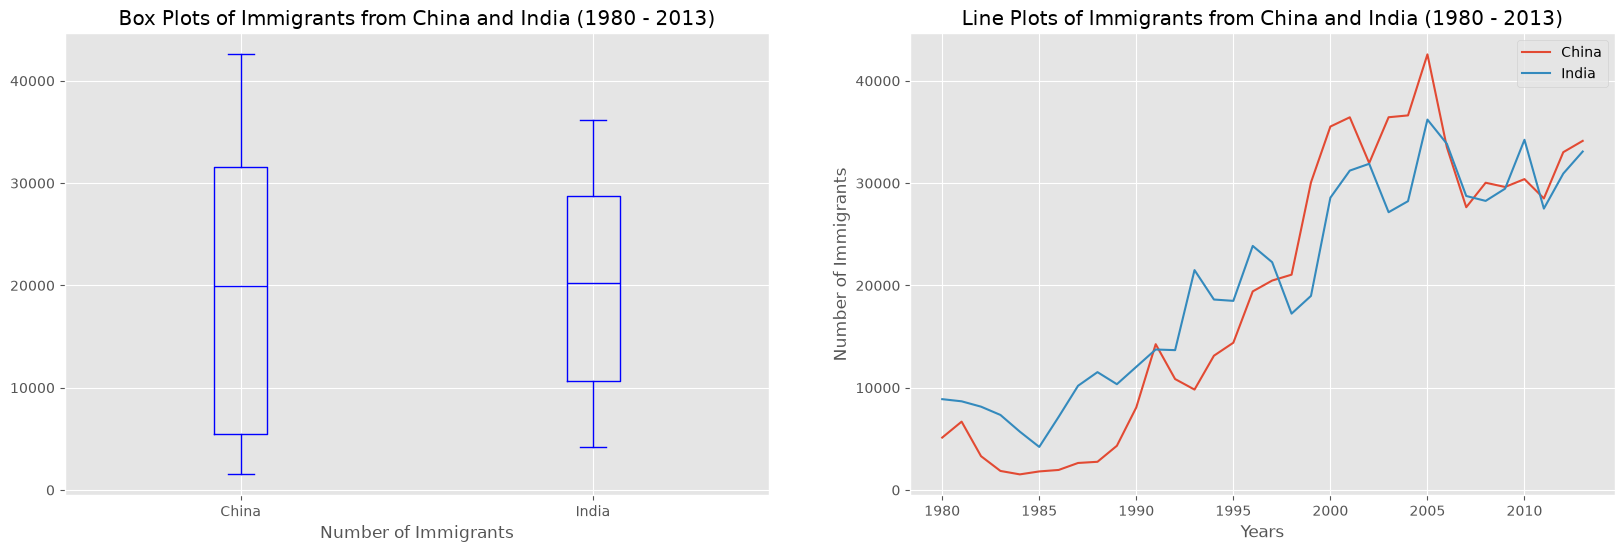

In [24]:
fig = plt.figure()  # create figure

ax0 = fig.add_subplot(1, 2, 1)  # add subplot 1 (1 row, 2 columns, first plot)
ax1 = fig.add_subplot(1, 2, 2)  # add subplot 2 (1 row, 2 columns, second plot)

# Subplot 1: Box Plot
df_CI.plot(kind="box", figsize=(20, 6), color="blue", ax=ax0)
ax0.set_title("Box Plots of Immigrants from China and India (1980 - 2013)")
ax0.set_xlabel("Number of Immigrants")
ax1.set_ylabel("Countries")

# Subplot 2: Line Plot
df_CI.plot(kind="line", figsize=(20, 6), ax=ax1)
ax1.set_title("Line Plots of Immigrants from China and India (1980 - 2013)")
ax1.set_ylabel("Number of Immigrants")
ax1.set_xlabel("Years")

plt.savefig(
    "../outputs/subplots_immigrant_china_india.png", dpi=200, bbox_inches="tight"
)
plt.show()

**Tips mengenai konvensi subplot**

Dalam kasus di mana `nrows`, `ncols`, dan `plot_number` semuanya kurang dari 10, ada cara mudah untuk memberikan angka 3 digit sebagai gantinya, di mana ratusan mewakili `nrows`, puluhan mewakili `ncols`, dan satuan mewakili `plot_number`. Misalnya,

```python
   subplot(211) == subplot(2, 1, 1) 
```

menghasilkan sub-axes dalam sebuah gambar yang mewakili plot teratas (yaitu yang pertama) dalam grid imajiner 2 baris kali 1 kolom (tidak ada grid yang sebenarnya ada, tetapi secara konseptual begitulah posisi sub-plot yang dikembalikan).


Mari kita coba sesuatu yang sedikit lebih canggih.

Sebelumnya kami telah mengidentifikasi 15 negara teratas berdasarkan total imigrasi dari tahun 1980 - 2013.

**Pertanyaan:** Buatlah diagram kotak (box plot) untuk memvisualisasikan distribusi 15 negara teratas (berdasarkan total imigrasi) yang dikelompokkan menurut *dekade* `1980-an`, `1990-an`, dan `2000-an`.


Langkah 1: Dapatkan dataset. Dapatkan 15 negara teratas berdasarkan total populasi imigran. Beri nama dataframe **df_top15**.

In [25]:
df_canada.sort_values("Total", axis=0, ascending=False, inplace=True)

df_top15 = df_canada.head(15)
df_top15

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
India,Asia,Southern Asia,Developing regions,8880,8670,8147,7338,5704,4211,7150,...,36210,33848,28742,28261,29456,34235,27509,30933,33087,691904
China,Asia,Eastern Asia,Developing regions,5123,6682,3308,1863,1527,1816,1960,...,42584,33518,27642,30037,29622,30391,28502,33024,34129,659962
United Kingdom of Great Britain and Northern Ireland,Europe,Northern Europe,Developed regions,22045,24796,20620,10015,10170,9564,9470,...,7258,7140,8216,8979,8876,8724,6204,6195,5827,551500
Philippines,Asia,South-Eastern Asia,Developing regions,6051,5921,5249,4562,3801,3150,4166,...,18139,18400,19837,24887,28573,38617,36765,34315,29544,511391
Pakistan,Asia,Southern Asia,Developing regions,978,972,1201,900,668,514,691,...,14314,13127,10124,8994,7217,6811,7468,11227,12603,241600
United States of America,Northern America,Northern America,Developed regions,9378,10030,9074,7100,6661,6543,7074,...,8394,9613,9463,10190,8995,8142,7676,7891,8501,241122
Iran (Islamic Republic of),Asia,Southern Asia,Developing regions,1172,1429,1822,1592,1977,1648,1794,...,5837,7480,6974,6475,6580,7477,7479,7534,11291,175923
Sri Lanka,Asia,Southern Asia,Developing regions,185,371,290,197,1086,845,1838,...,4930,4714,4123,4756,4547,4422,3309,3338,2394,148358
Republic of Korea,Asia,Eastern Asia,Developing regions,1011,1456,1572,1081,847,962,1208,...,5832,6215,5920,7294,5874,5537,4588,5316,4509,142581
Poland,Europe,Eastern Europe,Developed regions,863,2930,5881,4546,3588,2819,4808,...,1405,1263,1235,1267,1013,795,720,779,852,139241


Langkah 2: Buat dataframe baru yang berisi agregat untuk setiap dekade. Salah satu caranya adalah:

1.  Buatlah daftar semua tahun dalam dekade 80-an, 90-an, dan 00-an.
2.  Iris dataframe asli df_top15 untuk membuat rangkaian data untuk setiap dekade dan jumlahkan semua data untuk setiap negara selama bertahun-tahun.
3.  Gabungkan ketiga series tersebut ke dalam data frame baru. Beri nama data frame Anda **new_df**.

In [26]:
# 1: Buat daftar semua tahun dalam dekade
years_80s = list(map(str, range(1980, 1990)))
years_90s = list(map(str, range(1990, 2000)))
years_00s = list(map(str, range(2000, 2010)))

In [27]:
# 2: Potong dataframe asli df_top15 untuk membuat series untuk setiap dekade.
df_80s = df_top15.loc[:, years_80s].sum(axis=1)
df_90s = df_top15.loc[:, years_90s].sum(axis=1)
df_00s = df_top15.loc[:, years_00s].sum(axis=1)

In [28]:
# 3: Gabungkan ketiga series tersebut ke dalam dataframe baru
new_df = pd.DataFrame({"1980s": df_80s, "1990s": df_90s, "2000s": df_00s})

In [29]:
new_df

,1980s,1990s,2000s
India,82154,180395,303591
China,32003,161528,340385
United Kingdom of Great Britain and Northern Ireland,179171,261966,83413
Philippines,60764,138482,172904
Pakistan,10591,65302,127598
United States of America,76824,56915,75173
Iran (Islamic Republic of),21477,54871,65794
Sri Lanka,14796,70421,49678
Republic of Korea,16259,38189,68183
Poland,57602,64864,13629


Mari kita pelajari lebih lanjut tentang statistik yang terkait dengan dataframe menggunakan metode `describe()`.


In [30]:
new_df.describe()

,1980s,1990s,2000s
count,15.000000,15.000000,15.000000
mean,44418.333333,85594.666667,97471.533333
std,44190.676455,68237.560246,100583.204205
min,7613.000000,30028.000000,13629.000000
25%,16698.000000,39259.000000,36101.500000
50%,30638.000000,56915.000000,65794.000000
75%,59183.000000,104451.500000,105505.500000
max,179171.000000,261966.000000,340385.000000


Langkah 3: Buat box plot.

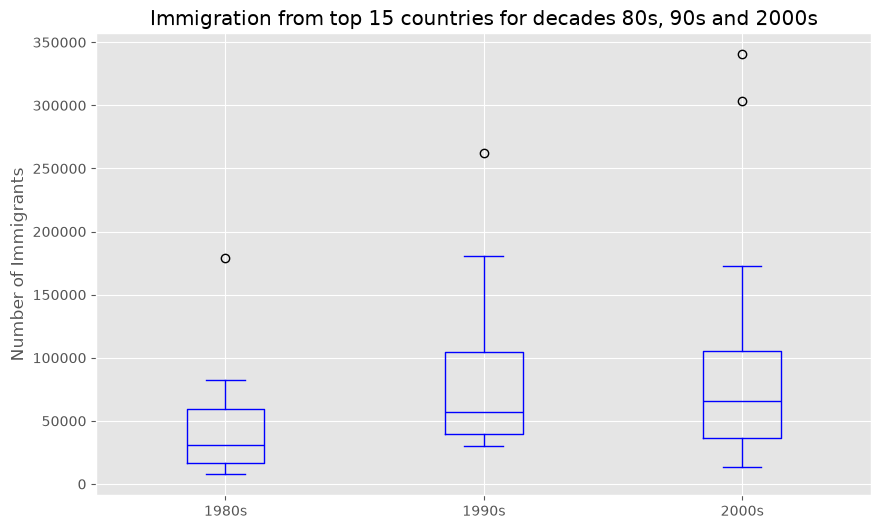

In [31]:
new_df.plot(kind="box", figsize=(10, 6), color="blue")

plt.title("Immigration from top 15 countries for decades 80s, 90s and 2000s")
plt.ylabel("Number of Immigrants")

plt.savefig("../outputs/box_plot_top_15_immigrant.png", dpi=200, bbox_inches="tight")
plt.show()

Perhatikan bagaimana box plot berbeda dari tabel ringkasan yang dibuat. Box plot memindai data dan mengidentifikasi data outlier. Agar menjadi data outlier, nilai data harus:<br>

*   lebih besar dari Q3 setidaknya 1,5 kali rentang interkuartil (IQR), atau,
*   lebih kecil dari Q1 setidaknya 1,5 kali IQR.

Mari kita ambil dekade 2000-an sebagai contoh: <br>

*   Q1 (25%) = 36,101.5 <br>
*   Q3 (75%) = 105,505.5 <br>
*   IQR = Q3 - Q1 = 69,404 <br>

Berdasarkan definisi outlier, setiap nilai yang lebih besar dari Q3 sebesar 1,5 kali IQR akan ditandai sebagai outlier.

Outlier > 105,505.5 + (1.5 \* 69,404) <br>
Outlier > 209,611.5


In [32]:
# mari kita periksa berapa banyak entri yang berada di atas ambang batas outlier.
new_df = new_df.reset_index()
new_df[new_df["2000s"] > 209611.5]

,index,1980s,1990s,2000s
0,India,82154,180395,303591
1,China,32003,161528,340385


China dan India sama-sama dianggap sebagai outliers karena populasi mereka selama dekade tersebut melebihi 209.611,5 jiwa.

Diagram kotak (box plot) adalah alat visualisasi tingkat lanjut, dan terdapat banyak pilihan dan penyesuaian yang melampaui cakupan praktikum ini. Silakan merujuk ke [Matplotlib documentation](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.boxplot.html) untuk informasi lebih lanjut.

# Scatter Plots <a id="10"></a>

Scatter plot atau diagram sebar(2D) adalah metode yang berguna untuk membandingkan variabel satu sama lain. Diagram sebar terlihat mirip dengan diagram garis karena keduanya memetakan variabel independen dan dependen pada grafik 2D. Sementara titik data dihubungkan oleh garis pada diagram garis, titik data tidak dihubungkan pada diagram sebar. Data dalam diagram sebar dianggap mengekspresikan suatu tren. Dengan analisis lebih lanjut menggunakan alat seperti regresi, kita dapat menghitung hubungan ini secara matematis dan menggunakannya untuk memprediksi tren di luar dataset.

Mari kita mulai dengan mengeksplorasi hal-hal berikut:

Dengan menggunakan `scatter plot`, mari kita visualisasikan tren total imigrasi ke Kanada (semua negara digabungkan) untuk tahun 1980 - 2013.


Langkah 1: Dapatkan dataset. Karena kita berharap untuk menggunakan hubungan antara `years` dan `total population`, kita akan mengkonversi `years` ke tipe `int`.


In [33]:
# Kita dapat menggunakan metode sum() untuk mendapatkan total populasi per tahun
df_total = pd.DataFrame(df_canada[years].sum(axis=0))

In [34]:
# Ubah tahun menjadi tipe int (berguna untuk regresi di kemudian hari)
df_total.index = map(int, df_total.index)

In [35]:
# Mengatur ulang indeks untuk memasukkannya kembali sebagai kolom dalam dataframe df_tot
df_total.reset_index(inplace=True)

In [36]:
# Mengganti nama kolom
df_total.columns = ["years", "total"]

# Lia dataframe terakhir
df_total.head()

,years,total
0,1980,99137
1,1981,110563
2,1982,104271
3,1983,75550
4,1984,73417


Langkah 2: Plot data. Di `Matplotlib`, kita dapat membuat set plot `scatter` dengan memberikan `kind='scatter'` sebagai argumen plot. Kita juga perlu memberikan kata kunci `x` dan `y` untuk menentukan kolom yang akan ditempatkan pada sumbu x dan y.


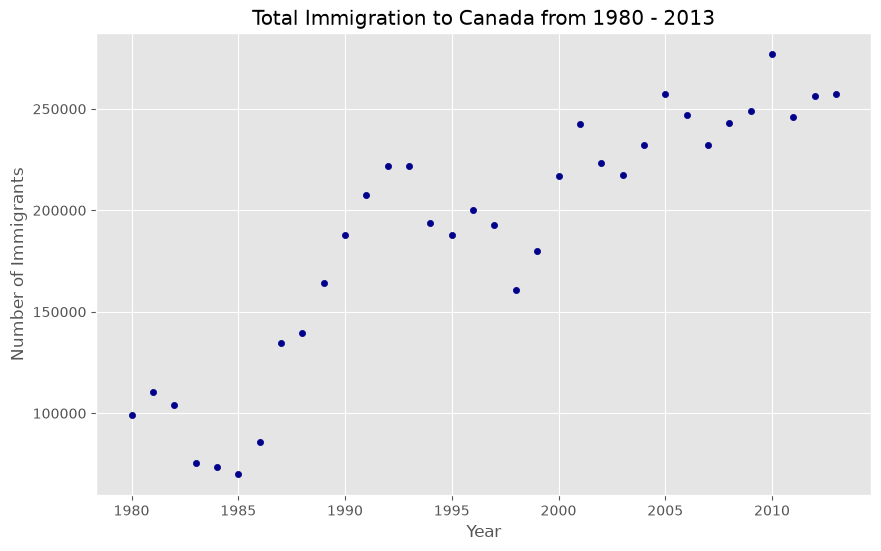

In [37]:
df_total.plot(kind="scatter", x="years", y="total", figsize=(10, 6), color="darkblue")

plt.title("Total Immigration to Canada from 1980 - 2013")
plt.xlabel("Year")
plt.ylabel("Number of Immigrants")

plt.savefig(
    "../outputs/scatter_plot_total_immigrants.png", dpi=200, bbox_inches="tight"
)
plt.show()

Perhatikan bagaimana diagram sebar (scatter plot) tidak menghubungkan titik-titik data. Kita dapat dengan jelas mengamati tren kenaikan pada data: seiring berjalannya waktu, jumlah total imigran meningkat. Kita dapat menganalisis tren kenaikan ini secara matematis menggunakan garis regresi (garis kecocokan terbaik).

Jadi, mari kita coba membuat garis linear yang paling sesuai, dan menggunakannya untuk memprediksi jumlah imigran pada tahun 2015.

Langkah 1: Dapatkan persamaan garis yang paling sesuai. Kita akan menggunakan metode `polyfit()` dari **Numpy** dengan memasukkan parameter berikut:

*   `x`: x-coordinates of the data.
*   `y`: y-coordinates of the data.
*   `deg`: Degree of fitting polynomial. 1 = linear, 2 = quadratic, and so on.


In [38]:
x = df_total["years"]  # years in x-axis
y = df_total["total"]  # total in y-axis

fit = np.polyfit(x, y, deg=1)
fit

array([ 5.56709228e+03, -1.09261952e+07])

Outputnya berupa array dengan koefisien polinomial, pangkat tertinggi terlebih dahulu. Karena kita memplot regresi linier `y = a * x + b`, output kita memiliki 2 elemen `[5.56709228e+03, -1.09261952e+07]` dengan kemiringan pada posisi 0 dan intersep pada posisi 1.

Langkah 2: Plot garis regresi pada `scatter plot`.

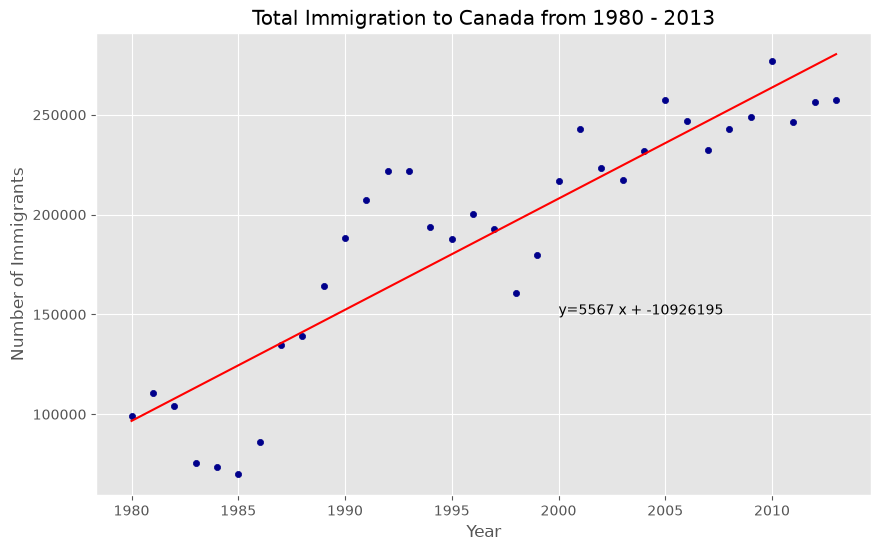

'No. Immigrants = 5567 * Year + -10926195'

In [39]:
df_total.plot(kind="scatter", x="years", y="total", figsize=(10, 6), color="darkblue")

plt.title("Total Immigration to Canada from 1980 - 2013")
plt.xlabel("Year")
plt.ylabel("Number of Immigrants")

# plot line of best fit
plt.plot(x, fit[0] * x + fit[1], color="red")  # recall that x is the Years
plt.annotate("y={0:.0f} x + {1:.0f}".format(fit[0], fit[1]), xy=(2000, 150000))

plt.savefig(
    "../outputs/scatter_with_line_plot_total_immigrants.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# print out the line of best fit
"No. Immigrants = {0:.0f} * Year + {1:.0f}".format(fit[0], fit[1])

Dengan menggunakan persamaan garis regresi terbaik, kita dapat memperkirakan jumlah imigran pada tahun 2015:

```python
No. Immigrants = 5567 * Year - 10926195
No. Immigrants = 5567 * 2015 - 10926195
No. Immigrants = 291,310
```

Jika dibandingkan dengan data sebenarnya dari Citizenship and Immigration Canada (CIC) [2016 Annual Report](http://www.cic.gc.ca/english/resources/publications/annual-report-2016/index.asp?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01), kita melihat bahwa Kanada menerima 271.845 imigran pada tahun 2015. Perkiraan nilai kita sebesar 291.310 berada dalam rentang 7% dari angka sebenarnya, yang cukup baik mengingat data asli kita berasal dari Perserikatan Bangsa-Bangsa (dan mungkin sedikit berbeda dari data CIC).

Sebagai catatan tambahan, kita dapat mengamati bahwa imigrasi mengalami penurunan sekitar tahun 1993-1997. Analisis lebih lanjut mengenai topik ini mengungkapkan bahwa pada tahun 1993 Kanada memperkenalkan RUU C-86 yang memperkenalkan revisi pada sistem penentuan status pengungsi, yang sebagian besar bersifat restriktif. Amandemen lebih lanjut terhadap Peraturan Imigrasi membatalkan persyaratan sponsor untuk "kerabat yang dibantu" dan mengurangi poin yang diberikan kepada mereka, sehingga mempersulit anggota keluarga (selain keluarga inti) untuk berimigrasi ke Kanada. Langkah-langkah restriktif ini berdampak langsung pada angka imigrasi selama beberapa tahun berikutnya.


**Pertanyaan**: Buatlah diagram sebar (scatter plot) dari total imigrasi dari Denmark, Norway, dan Sweden ke Canada dari tahun 1980 hingga 2013?

**Langkah 1**: Dapatkan datanya:

1.  Buatlah sebuah dataframe yang hanya berisi angka-angka yang terkait dengan Denmark, Norway, dan Sweden. Beri nama **df_countries**.
2.  Jumlahkan angka imigrasi di ketiga negara tersebut untuk setiap tahunnya dan ubah hasilnya menjadi sebuah dataframe. Beri nama dataframe baru ini **df_total2**.
3.  Atur ulang indeks di tempatnya.
4.  Ubah nama kolom menjadi **tahun** dan **total**.
5.  Tampilkan dataframe hasilnya.


In [40]:
# buat dataframe yang hanya berisi jumlah imigrasi dari negara Denmark, Norway, dan Sweden
df_countries = df_canada.loc[["Denmark", "Norway", "Sweden"], years].transpose()
df_countries.head()

,Denmark,Norway,Sweden
1980,272,116,281
1981,293,77,308
1982,299,106,222
1983,106,51,176
1984,93,31,128


In [41]:
# Jumlahkan angka imigrasi tiap tahun dari ketiga negara tersebut
df_total2 = pd.DataFrame(df_countries.sum(axis=1))
df_total2.head()

,0
1980,669
1981,678
1982,627
1983,333
1984,252


In [42]:
# atur ulang index
df_total2.reset_index(inplace=True)

In [43]:
# ubah nama kolom menjadi "years" dan "total"
df_total2.columns = ["year", "total"]

# ubah kolom tahun dari string menjadi integer untuk membuat scatter plot.
df_total2["year"] = df_total2["year"].astype(int)

# hasil dataframe terakhir
df_total2.head()

,year,total
0,1980,669
1,1981,678
2,1982,627
3,1983,333
4,1984,252


**Langkah 2**: Buat scatter plot dengan memplot total terhadap tahun di **df_total2**.

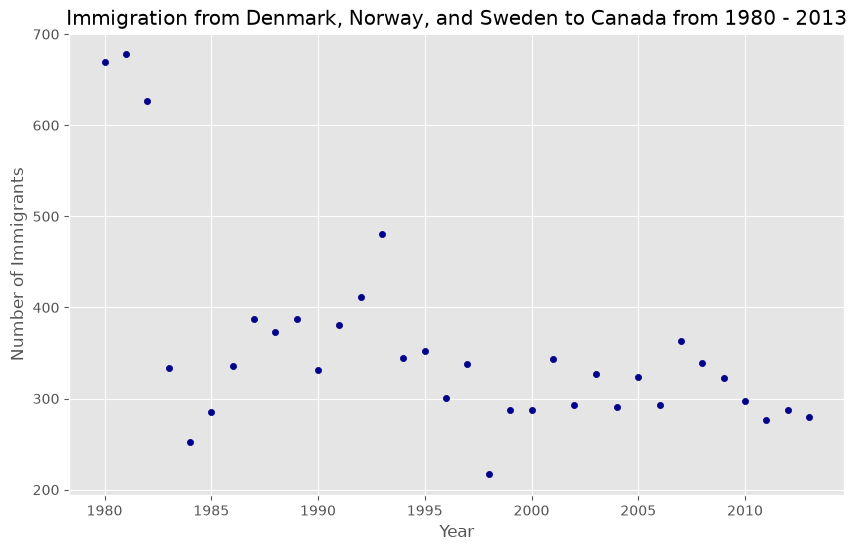

In [44]:
df_total2.plot(kind="scatter", x="year", y="total", figsize=(10, 6), color="darkblue")

plt.title("Immigration from Denmark, Norway, and Sweden to Canada from 1980 - 2013")
plt.xlabel("Year")
plt.ylabel("Number of Immigrants")

plt.savefig(
    "../outputs/scatter_plot_immigrants_denmark_norway_sweden.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# Bubble Plots <a id="12"></a>

`Bubble plot` adalah variasi dari `scatter plot` yang menampilkan tiga dimensi data (x, y, z). Titik data digantikan dengan gelembung, dan ukuran gelembung ditentukan oleh variabel ketiga `z`, yang juga dikenal sebagai bobot. Dalam `maplotlib`, kita dapat memasukkan array atau skalar ke parameter `s` pada `plot()`, yang berisi bobot setiap titik.

**Mari kita mulai dengan menganalisis dampak Depresi Besar Argentina.**.

Argentina mengalami depresi besar dari tahun 1998 hingga 2002, yang menyebabkan pengangguran meluas, kerusuhan, jatuhnya pemerintah, dan gagal bayar utang luar negeri negara tersebut. Dari segi pendapatan, lebih dari 50% penduduk Argentina miskin, dan tujuh dari sepuluh anak Argentina miskin pada puncak krisis tahun 2002.

Mari kita analisis dampak krisis ini, dan bandingkan imigrasi Argentina dengan imigrasi negara tetangganya, Brazil. Mari kita lakukan itu menggunakan `bubble plot` imigrasi dari Brasil dan Argentina untuk tahun 1980 - 2013. Kita akan menetapkan bobot untuk bubble tersebut sebagai nilai *normalisasi* populasi untuk setiap tahunnya.


**Langkah 1**: Dapatkan data untuk Brazil dan Argentina. Seperti pada contoh sebelumnya, kita akan mengkonversi `Tahun` ke tipe int dan memasukkannya ke dalam dataframe.

In [45]:
# transposed dataframe
df_canada_t = df_canada[years].transpose()

# ubah Tahun (indeks) menjadi tipe int
df_canada_t.index = map(int, df_canada_t.index)

In [46]:
# Mari kita beri label pada indeks. Ini akan otomatis menjadi nama kolom saat kita mengatur ulang indeks.
df_canada_t.index.name = "Year"

In [47]:
# Atur ulang indeks untuk menampilkan Tahun sebagai kolom.
df_canada_t.reset_index(inplace=True)

# Lihat perubahannya
df_canada_t.head()

,Year,India,China,United Kingdom of Great Britain and Northern Ireland,Philippines,Pakistan,United States of America,Iran (Islamic Republic of),Sri Lanka,Republic of Korea,...,Kiribati,Vanuatu,Sao Tome and Principe,Tuvalu,American Samoa,New Caledonia,San Marino,Marshall Islands,Western Sahara,Palau
0,1980,8880,5123,22045,6051,978,9378,1172,185,1011,...,0,0,0,0,0,0,1,0,0,0
1,1981,8670,6682,24796,5921,972,10030,1429,371,1456,...,0,0,0,1,1,0,0,0,0,0
2,1982,8147,3308,20620,5249,1201,9074,1822,290,1572,...,0,0,0,0,0,0,0,0,0,0
3,1983,7338,1863,10015,4562,900,7100,1592,197,1081,...,1,0,0,0,0,0,0,0,0,0
4,1984,5704,1527,10170,3801,668,6661,1977,1086,847,...,0,0,0,1,0,0,0,0,0,0


**Langkah 2**: Buat bobot yang dinormalisasi.

Ada beberapa metode normalisasi dalam statistik, masing-masing dengan kegunaannya sendiri. Dalam kasus ini, kita akan menggunakan [feature scaling](https://en.wikipedia.org/wiki/Feature_scaling?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01) untuk membawa semua nilai ke dalam rentang \[0, 1]. Rumus umumnya adalah:

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/Mod3Fig3FeatureScaling.png" align="center">

di mana $X$ adalah nilai asli, $X'$ adalah nilai yang dinormalisasi. Rumus tersebut menetapkan nilai maksimum dalam dataset menjadi 1, dan menetapkan nilai minimum menjadi 0. Sisa titik data diskalakan ke nilai antara 0-1 sesuai dengan itu.


In [48]:
# menormalisasi data negara Brasil
norm_brazil = (df_canada_t["Brazil"] - df_canada_t["Brazil"].min()) / (
    df_canada_t["Brazil"].max() - df_canada_t["Brazil"].min()
)

In [49]:
# menormalisasi data negara Argentina
norm_argen = (df_canada_t["Argentina"] - df_canada_t["Argentina"].min()) / (
    df_canada_t["Argentina"].max() - df_canada_t["Argentina"].min()
)

**Langkah 3**: Buat grafik data.

*   Untuk membuat dua plot sebaran berbeda dalam satu plot, kita dapat menyertakan sumbu dari satu plot ke plot lainnya dengan meneruskannya melalui parameter `ax`.
*   Kita juga akan memasukkan bobot menggunakan parameter `s`. Karena bobot yang dinormalisasi berada antara 0-1, bobot tersebut tidak akan terlihat pada plot. Oleh karena itu, kita akan:
    *   kalikan berat dengan 2000 untuk memperbesar skalanya pada grafik, dan,
    *   tambahkan 10 untuk mengimbangi nilai minimum (yang memiliki bobot 0 dan karenanya berskala dengan $\times 2000$).


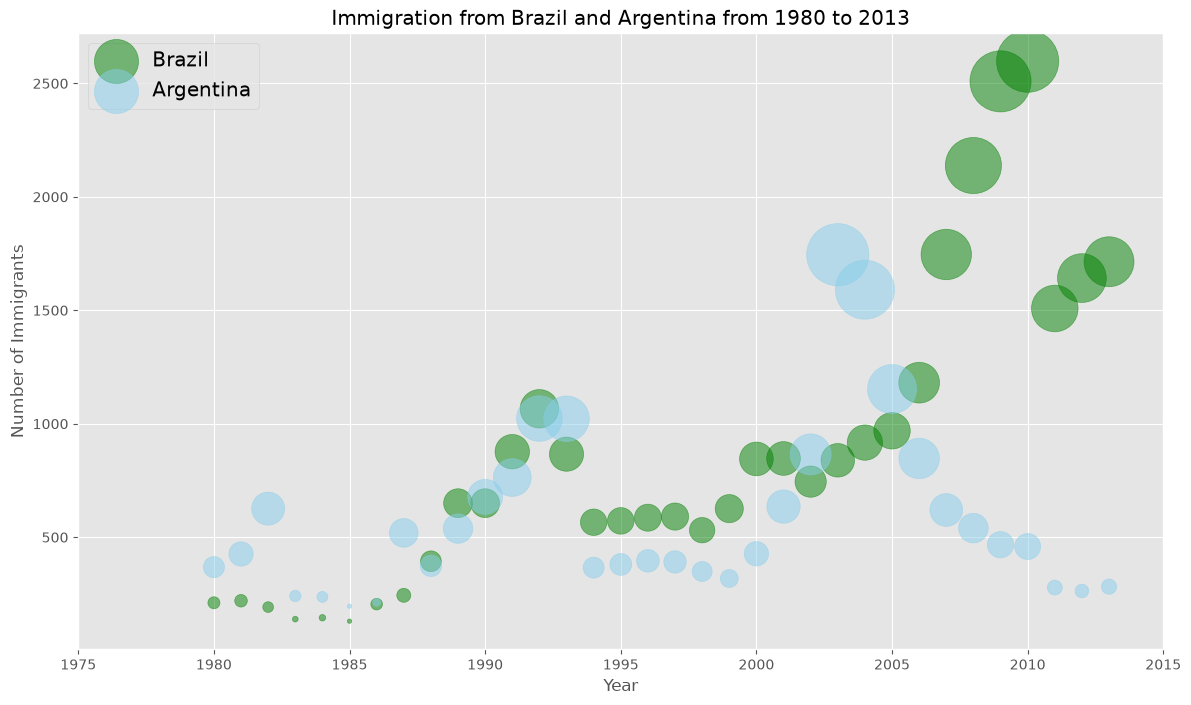

In [50]:
# Plot Brazil
ax0 = df_canada_t.plot(
    kind="scatter",
    x="Year",
    y="Brazil",
    figsize=(14, 8),
    alpha=0.5,  # transparancy
    color="green",
    s=norm_brazil * 2000 + 10,  # pass in weights
    xlim=(1975, 2015),
)

# Plot Argentina
ax1 = df_canada_t.plot(
    kind="scatter",
    x="Year",
    y="Argentina",
    alpha=0.5,
    color="skyblue",
    s=norm_argen * 2000 + 10,
    ax=ax0,
)

ax0.set_ylabel("Number of Immigrants")
ax0.set_title("Immigration from Brazil and Argentina from 1980 to 2013")
ax0.legend(["Brazil", "Argentina"], loc="upper left", fontsize="x-large")

plt.savefig(
    "../outputs/bubble_plots_immigrant_brazil_argentina.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

Ukuran gelembung tersebut sesuai dengan besarnya populasi imigran pada tahun tersebut, dibandingkan dengan data tahun 1980-2013. Semakin besar gelembungnya, semakin banyak imigran pada tahun tersebut.

Dari grafik di atas, kita dapat melihat peningkatan imigrasi dari Argentina selama Depresi Besar 1998-2002. Kita juga dapat mengamati lonjakan serupa sekitar tahun 1985 hingga 1993. Bahkan, Argentina telah mengalami Depresi Besar dari tahun 1974 hingga 1990, tepat sebelum dimulainya Depresi Besar 1998-2002.

Dalam konteks yang serupa, Brasil mengalami *Samba Effect* di mana real Brasil (mata uang) anjlok hampir 35% pada tahun 1999. Ada kekhawatiran akan krisis keuangan Amerika Selatan karena banyak negara Amerika Selatan sangat bergantung pada ekspor industri dari Brasil. Pemerintah Brasil kemudian mengadopsi program penghematan, dan ekonomi perlahan pulih selama bertahun-tahun, yang berpuncak pada lonjakan pada tahun 2010. Data imigrasi mencerminkan peristiwa-peristiwa ini.

**Pertanyaan**: Sebelumnya di lab ini, kita telah membuat box plot untuk membandingkan imigrasi dari China dan India ke Canada. Buatlah bubble plot imigrasi dari China dan India untuk memvisualisasikan perbedaan seiring waktu dari tahun 1980 hingga 2013. Anda dapat menggunakan **df_canada_t** yang telah kita definisikan dan gunakan pada contoh sebelumnya.


Langkah 1: Normalisasi data yang berkaitan dengan China dan India.

In [51]:
# menormalisasi data negara China
norm_china = (df_canada_t["China"] - df_canada_t["China"].min()) / (
    df_canada_t["China"].max() - df_canada_t["China"].min()
)

In [52]:
# menormalisasi data negara India
norm_india = (df_canada_t["India"] - df_canada_t["India"].min()) / (
    df_canada_t["India"].max() - df_canada_t["India"].min()
)

Langkah 2: Hasilkan plot gelembung.

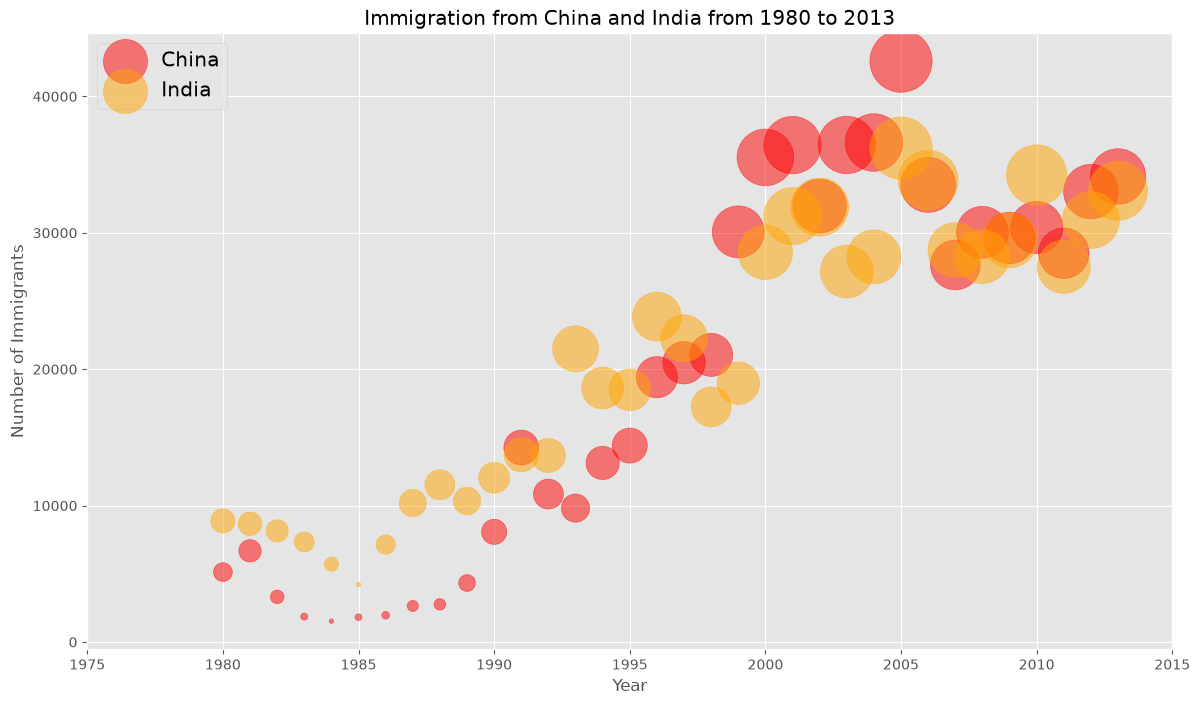

In [53]:
# Plot China
ax0 = df_canada_t.plot(
    kind="scatter",
    x="Year",
    y="China",
    figsize=(14, 8),
    alpha=0.5,
    color="red",
    s=norm_china * 2000 + 10,
    xlim=(1975, 2015),
)

# Plot India
ax1 = df_canada_t.plot(
    kind="scatter",
    x="Year",
    y="India",
    alpha=0.5,
    color="orange",
    s=norm_india * 2000 + 10,
    ax=ax0,
)

ax0.set_ylabel("Number of Immigrants")
ax0.set_title("Immigration from China and India from 1980 to 2013")
ax0.legend(["China", "India"], loc="upper left", fontsize="x-large")

plt.savefig(
    "../outputs/bubble_plots_immigrant_china_india.png", dpi=200, bbox_inches="tight"
)
plt.show()